<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula4-exercicio2-quase-so-ruido.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 4, exercício 2: Quase só ruído

Qual é o `alpha_bar` no passo 999?

A pergunta usa o que a aula [4. O ruído entra, e o modelo tira](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/04-difusao-ruido-e-passos.ipynb) deixa pronto. **Ambiente de execução → Executar tudo** carrega isso, deixa uma célula para tentar e, no fim, confere uma solução.

In [1]:
import sys
!{sys.executable} -m pip install -q diffusers transformers accelerate matplotlib pillow

## Preparação

A preparação estraga a foto do ônibus com ruído, sem rede, e o SD-Turbo tira esse ruído em quatro passos. Ficam prontos `alpha_bar`, `limpa`, `com_ruido` e `passos_modelo`.

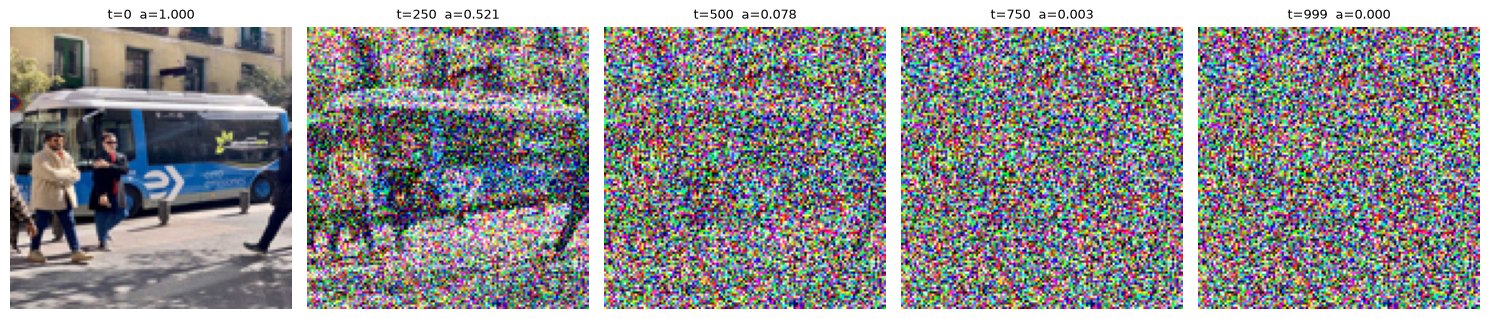

alpha_bar[0]=0.9999  alpha_bar[999]=0.0000


In [2]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def faixa(imagens, titulos):
    plt.figure(figsize=(3 * len(imagens), 3.2))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, len(imagens), i + 1)
        if torch.is_tensor(img):
            vis = img.detach().permute(1, 2, 0).clamp(-1, 1)
            vis = ((vis + 1) / 2).numpy()
        else:
            vis = img
        plt.imshow(vis)
        plt.title(titulo, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


foto = Image.open(baixar("https://www.ultralytics.com/images/bus.jpg", "onibus.jpg")).convert("RGB")
arr = torch.from_numpy(np.asarray(foto.resize((128, 128))).copy()).float()
limpa = arr.permute(2, 0, 1) / 255 * 2 - 1

betas = torch.linspace(1e-4, 0.02, 1000)
alpha_bar = torch.cumprod(1 - betas, dim=0)


def com_ruido(x, t, semente=0):
    g = torch.Generator().manual_seed(semente)
    ruido = torch.randn(x.shape, generator=g)
    a = alpha_bar[t]
    return a.sqrt() * x + (1 - a).sqrt() * ruido


tempos = [0, 250, 500, 750, 999]
faixa(
    [com_ruido(limpa, t) for t in tempos],
    [f"t={t}  a={float(alpha_bar[t]):.3f}" for t in tempos],
)
print(f"alpha_bar[0]={float(alpha_bar[0]):.4f}  alpha_bar[999]={float(alpha_bar[999]):.4f}")

In [3]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from diffusers import AutoPipelineForImage2Image, AutoPipelineForText2Image
from diffusers.utils import logging as diffusers_logging
from PIL import Image

diffusers_logging.set_verbosity_error()

MODELO = "stabilityai/sd-turbo"


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda", torch.float16
    if torch.backends.mps.is_available():
        return "mps", torch.float32
    return "cpu", torch.float32


def carregar():
    device, dtype = dispositivo()
    extra = {"variant": "fp16"} if device == "cuda" else {}
    try:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, dtype=dtype, **extra)
    except TypeError:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, torch_dtype=dtype, **extra)
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    if device == "cpu":
        print("CPU: cada imagem pode levar alguns minutos. No Colab, troque o ambiente para T4.")
    print("dispositivo:", device)
    return pipe


def grade(imagens, titulos):
    n = len(imagens)
    plt.figure(figsize=(3.1 * n, 3.4))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(titulo, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


pipe = carregar()


def gerar(texto, semente=0, n_passos=2):
    g = torch.Generator(device="cpu").manual_seed(semente)
    return pipe(
        texto,
        num_inference_steps=n_passos,
        guidance_scale=0.0,
        generator=g,
    ).images[0]

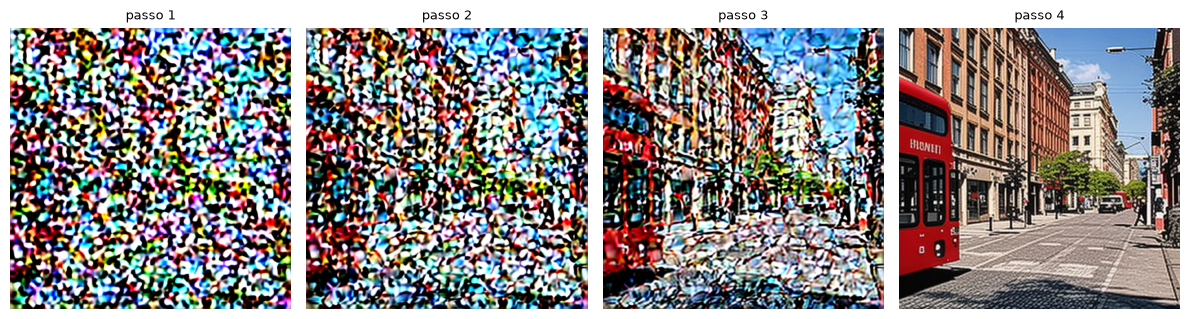

quadros da volta: 4


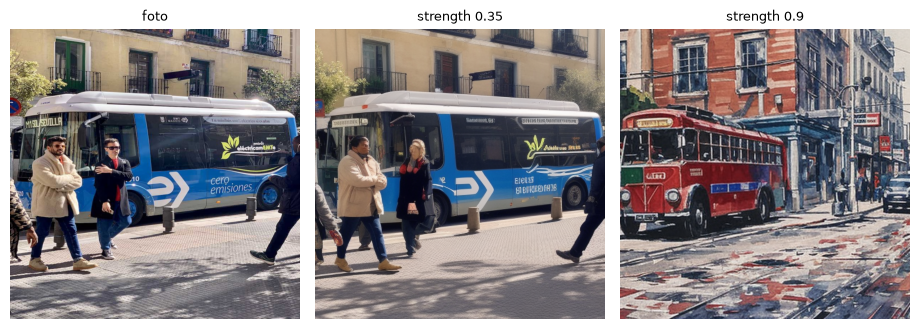

In [4]:
passos_modelo = []


def guardar_passo(pipe, passo, tempo, callback_kwargs):
    latentes = callback_kwargs["latents"].to(pipe.vae.dtype)
    with torch.no_grad():
        imagem = pipe.vae.decode(latentes / pipe.vae.config.scaling_factor).sample
    vis = ((imagem[0].clamp(-1, 1) + 1) / 2).permute(1, 2, 0).detach().cpu().float().numpy()
    passos_modelo.append(vis)
    return callback_kwargs


g = torch.Generator(device="cpu").manual_seed(0)
pipe(
    "a red city bus on a sunny street, photo",
    num_inference_steps=4,
    guidance_scale=0.0,
    generator=g,
    callback_on_step_end=guardar_passo,
    callback_on_step_end_tensor_inputs=["latents"],
)
faixa(passos_modelo, [f"passo {i + 1}" for i in range(len(passos_modelo))])
print("quadros da volta:", len(passos_modelo))

img2img = AutoPipelineForImage2Image.from_pipe(pipe)
origem = foto.resize((512, 512))
prompt_pintura = "a watercolor painting of a red bus on a street"
resultados = [origem]
titulos = ["foto"]
for forca in (0.35, 0.9):
    g = torch.Generator(device="cpu").manual_seed(0)
    resultados.append(img2img(
        prompt_pintura,
        image=origem,
        strength=forca,
        num_inference_steps=4,
        guidance_scale=0.0,
        generator=g,
    ).images[0])
    titulos.append(f"strength {forca}")
grade(resultados, titulos)

In [5]:
# @title Correção automática (rode, não precisa ler)
_a0 = float(alpha_bar[0])
_a999 = float(alpha_bar[999])
_e0 = float((com_ruido(limpa, 0) - limpa).abs().mean())
_e999 = float((com_ruido(limpa, 999) - limpa).abs().mean())

VERIFICAR = {
    1: lambda r: abs(float(r) - _a0) < 1e-5,
    2: lambda r: abs(float(r) - _a999) < 1e-5,
    3: lambda r: tuple(int(x) for x in r) == tuple(limpa.shape),
    4: lambda r: bool(r) is True and _e999 > _e0,
    5: lambda r: int(r) == len(passos_modelo),
    6: lambda r: tuple(int(x) for x in r) == (int(4 * 0.35), int(4 * 0.9)),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Qual é o `alpha_bar` no passo 999?

*Dica:* O último índice de uma escala de 1000 passos é 999.

Troque o `None` pela sua resposta e rode a célula.

In [6]:
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [7]:
resposta = float(alpha_bar[999])

conferir(2, resposta)

Exercício 2: ✅ certo!


## O que fica

Próximo: [Aula 4, exercício 3: O tamanho não muda](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula4-exercicio3-o-tamanho-nao-muda.ipynb).